# Plotting SlipTaper results

This notebook shows

1. **how the slip of a single patch tapers to zero** at the edge of that patch (map view and profiles along strike and down dip), and
2. **that the patches sum to uniform slip** across the whole fault, apart from the very edge of the fault where there are no neighbouring patches to take over.

`taper.x` produces one patch per run: slip is centred on the quadrangle `cell` in `input.txt` and tapers into its neighbours. Part 2 therefore runs `taper.x` once for every quadrangle in the mesh and adds the results.

**Mesh file:** `taper.x` needs the cells of the mesh file in a particular order (one row of cells after another, each cell followed by its along-strike neighbour, nodes 1,4 on the deep edge and 2,3 on the shallow edge). A mesh with the right node order inside each cell but the wrong order of cells fails for many cells, with an out-of-bounds error if `taper.x` is built with the debug flags and garbage output if it is not. `order_mesh.py` puts any mesh into the right order and this notebook applies it first, so `MESH_IN` can be any of the mesh files. Cell numbers refer to the re-ordered mesh.

**Before running:** compile the code (`make` in `../src`) so that `../src/taper.x` exists. The notebook is meant to sit in `example/` next to `input.txt` and the mesh file.

## Set up

In [2]:
import re
import subprocess
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from order_mesh import raster_order, describe_changes
from matplotlib.path import Path as MplPath
from matplotlib.tri import Triangulation

# --- settings --------------------------------------------------------------
EXE       = Path('../src/taper.x')      # compiled SlipTaper executable
INPUT     = Path('input.txt')           # template input file (its `cell` is overwritten per run)
MESH_IN   = Path('southamerica_quadrilateral_coords_ordered.dat')   # quadrangle mesh (overrides the name in input.txt)
RUN_DIR   = Path('patches')             # all patch outputs are written here
PLOT_CELL = 144                         # patch used for the single-patch plots in part 1

## Helper functions

The mesh file holds one quadrangle per line: `lon1 lat1 z1 lon2 lat2 z2 lon3 lat3 z3 lon4 lat4 z4`.
Nodes 1→4 run along strike and 1→2 down dip.

In [3]:
def taper_length_km(input_file=INPUT):
    """Taper distance from &MESHGRID, converted from metres to km."""
    txt = Path(input_file).read_text()
    val = re.search(r'taper\s*=\s*([0-9.eEdD+-]+)', txt).group(1)
    return float(val.lower().replace('d', 'e')) / 1e3


def read_quads(path):
    """Return an (ncell, 4, 3) array of [lon, lat, z] for the 4 nodes of each quadrangle."""
    return np.loadtxt(path).reshape(-1, 4, 3)


def read_vtk(path):
    """Read a slip_taper_geo_NNN.vtk file written by SlipTaper.

    Returns lon, lat, depth (per node), tris (ntri, 3 node indices) and slip (per triangle).
    The vtk points are stored as (lat, lon, depth).
    """
    lines = Path(path).read_text().splitlines()

    i = next(k for k, l in enumerate(lines) if l.startswith('POINTS'))
    npts = int(lines[i].split()[1])
    pts = np.array([l.split() for l in lines[i + 1:i + 1 + npts]], dtype=float)

    i = next(k for k, l in enumerate(lines) if l.startswith('CELLS'))
    ncell = int(lines[i].split()[1])
    tris = np.array([l.split()[1:4] for l in lines[i + 1:i + 1 + ncell]], dtype=int)

    # cell data: the first scalar after CELL_DATA is the slip
    i = next(k for k, l in enumerate(lines) if l.startswith('CELL_DATA'))
    j = next(k for k in range(i, len(lines)) if lines[k].startswith('LOOKUP_TABLE'))
    vals = ' '.join(lines[j + 1:]).split()
    slip = np.array(vals[:ncell], dtype=float)

    return pts[:, 1], pts[:, 0], pts[:, 2], tris, slip


def run_patch(cell, force=False):
    """Run taper.x for one quadrangle and return the path of the geographic vtk file."""
    out = RUN_DIR / f'slip_taper_geo_{cell:03d}.vtk'
    if out.exists() and not force:
        return out

    RUN_DIR.mkdir(exist_ok=True)

    txt = INPUT.read_text()
    txt = re.sub(r"(name\s*=\s*)'[^']*'", rf"\g<1>'{MESH.name}'", txt)
    txt = re.sub(r'(cell\s*=\s*)\d+', rf'\g<1>{cell}', txt)
    txt = re.sub(r'(verbose\s*=\s*)\d+', r'\g<1>0', txt)      # only the lon/lat outputs
    (RUN_DIR / 'input.txt').write_text(txt)

    res = subprocess.run([str(EXE.resolve())], cwd=RUN_DIR, capture_output=True, text=True)
    if res.returncode != 0 or not out.exists():
        raise RuntimeError(f'taper.x failed for cell {cell}:\n{res.stdout[-500:]}\n{res.stderr[-500:]}')
    return out


def set_geo_aspect(ax, lat0):
    """Make 1 degree of latitude look as long as 1 degree of longitude x cos(lat)."""
    ax.set_aspect(1 / np.cos(np.radians(lat0)))

## Read the mesh

The mesh is put into the order `taper.x` needs and saved in `RUN_DIR`, which is where all the runs happen.

In [4]:
RUN_DIR.mkdir(exist_ok=True)
quads_in = read_quads(MESH_IN)
quads, row_lengths, source = raster_order(quads_in, return_source=True)
print(describe_changes(quads_in, quads, source, row_lengths))
MESH = RUN_DIR / f'{MESH_IN.stem}_ordered.dat'
new_text = '\n'.join(' '.join(f'{v:.6f}' for v in q.ravel()) for q in quads) + '\n'
if not MESH.exists() or MESH.read_text() != new_text:     # different mesh: earlier patches are out of date
    for old in RUN_DIR.glob('slip_taper_*'):
        old.unlink()
    MESH.write_text(new_text)

ncells = len(quads)
lon0, lat0 = quads[:, :, 0].mean(), quads[:, :, 1].mean()
print(f'{ncells} quadrangles in {MESH.name}, taper = {taper_length_km():.1f} km')

660 cells in 4 rows: [165, 165, 165, 165]
The mesh was already in the correct order: nothing was changed.
660 quadrangles in southamerica_quadrilateral_coords_ordered_ordered.dat, taper = 15.0 km


## 1. Slip of a single patch

Run `taper.x` for `PLOT_CELL` and plot the triangular mesh coloured by slip. Black outlines are the original quadrangles and the slipping quadrangle is in red.

1200 triangles, slip range 0.000 - 1.000


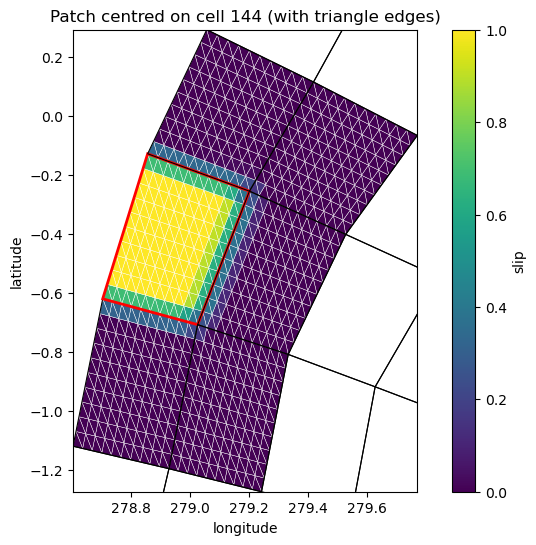

In [16]:
# same as the plot above, with the triangle edges drawn in white
lon, lat, dep, tris, slip = read_vtk(run_patch(PLOT_CELL))
print(f'{len(tris)} triangles, slip range {slip.min():.3f} - {slip.max():.3f}')

fig, ax = plt.subplots(figsize=(9, 6))
tpc = ax.tripcolor(Triangulation(lon, lat, tris), facecolors=slip, cmap='viridis', edgecolors='white', linewidth=0.3)
fig.colorbar(tpc, ax=ax, label='slip')

# outline the original quadrangles that overlap the plotted area
for n, q in enumerate(quads, start=1):
    inside = (q[:, 0].max() >= lon.min()) & (q[:, 0].min() <= lon.max()) & \
             (q[:, 1].max() >= lat.min()) & (q[:, 1].min() <= lat.max())
    if inside:
        ax.fill(q[:, 0], q[:, 1], fill=False, edgecolor='red' if n == PLOT_CELL else 'k',
                lw=2 if n == PLOT_CELL else 0.8)

ax.set_xlim(lon.min(), lon.max())
ax.set_ylim(lat.min(), lat.max())
set_geo_aspect(ax, lat.mean())
ax.set(xlabel='longitude', ylabel='latitude', title=f'Patch centred on cell {PLOT_CELL} (with triangle edges)')
plt.show()

### Profiles through the centre of the patch

Slip is sampled along a line through the centre of the slipping quadrangle, once along strike (node 1→4) and once down dip (node 1→2), out to 2.5 quadrangle lengths either side. The dashed lines are the edges of the slipping quadrangle. Slip is 0 outside the patch.

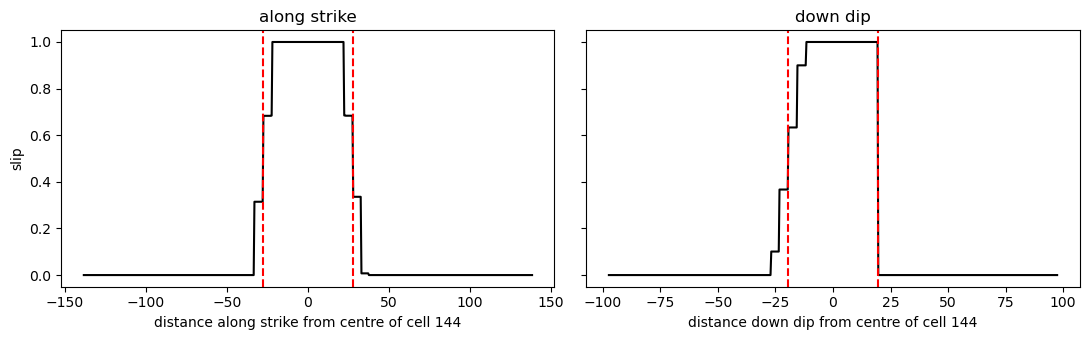

In [17]:
def sample_slip(tri, slip, xs, ys):
    """Slip of the triangle containing each point (0 outside the mesh)."""
    idx = tri.get_trifinder()(xs, ys)
    return np.where(idx >= 0, slip[np.clip(idx, 0, None)], 0.0)


q = quads[PLOT_CELL - 1]
centre = q[:, :2].mean(axis=0)
strike = (q[3, :2] - q[0, :2] + q[2, :2] - q[1, :2]) / 2    # lon/lat vector across the quad, along strike
dip    = (q[1, :2] - q[0, :2] + q[2, :2] - q[3, :2]) / 2    # lon/lat vector across the quad, down dip

def length_km(v):
    return np.hypot(v[0] * 111.32 * np.cos(np.radians(centre[1])), v[1] * 110.57)

tri = Triangulation(lon, lat, tris)
t = np.linspace(-2.5, 2.5, 600)          # position in units of quadrangle length

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, vec, name in zip(axes, (strike, dip), ('along strike', 'down dip')):
    pts = centre + t[:, None] * vec
    L = length_km(vec)
    ax.plot(t * L, sample_slip(tri, slip, pts[:, 0], pts[:, 1]), 'k')
    ax.axvline(-L / 2, ls='--', c='r'); ax.axvline(L / 2, ls='--', c='r')
    ax.set(xlabel=f'distance {name} from centre of cell {PLOT_CELL}', title=name)
axes[0].set_ylabel('slip')
plt.tight_layout()
plt.show()

## 2. Sum of all patches

Run `taper.x` for every quadrangle (a few tens of milliseconds each; finished patches are reused, so re-running the cell is quick). Each patch is then sampled onto a regular lon/lat grid and the patches are added.
Sampling onto a grid means the patches do not need to share identical triangles.

In [18]:
failed = []
for c in range(1, ncells + 1):
    try:
        run_patch(c)
    except RuntimeError as err:
        failed.append(c)
        print(err)
print(f'{ncells - len(failed)} of {ncells} patches available; failed: {failed}')

# a patch with no slip at all means taper.x ran on a mesh it could not handle
empty = [c for c in range(1, ncells + 1) if c not in failed and read_vtk(run_patch(c))[4].max() <= 0]
print(f'patches without any slip: {empty}')

660 of 660 patches available; failed: []
patches without any slip: []


In [8]:
# Resolution of the plotting grid used to add up the patches. This only affects this notebook:
# it is not related to nx_cells / nz_cells in input.txt, which set how many triangles each
# quadrangle is split into inside taper.x.
#
# The longest side of the lon/lat bounding box of the fault is divided into NGRID steps and the
# same step is used in both directions. Each patch is sampled at these grid points and the
# samples are added. For a 66 degree long fault, NGRID = 800 gives a 0.08 degree (about 9 km)
# step, which is coarser than the triangles (cells are ~40 km across, so triangles are ~4 km).
# That is enough to show that the sum is flat, but to resolve the taper at the edge of the
# fault use a larger value (e.g. 2000). Run time and memory grow roughly as NGRID**2.
NGRID = 2000

lon_min, lon_max = quads[:, :, 0].min(), quads[:, :, 0].max()
lat_min, lat_max = quads[:, :, 1].min(), quads[:, :, 1].max()
step = max(lon_max - lon_min, lat_max - lat_min) / NGRID
gx = np.arange(lon_min, lon_max + step, step)
gy = np.arange(lat_min, lat_max + step, step)
GX, GY = np.meshgrid(gx, gy)

# grid points that are inside the fault (inside any quadrangle)
on_fault = np.zeros(GX.shape, dtype=bool)
for q in quads:
    path = MplPath(q[:, :2])
    j0, j1 = np.searchsorted(gx, [q[:, 0].min(), q[:, 0].max()])
    i0, i1 = np.searchsorted(gy, [q[:, 1].min(), q[:, 1].max()])
    sub = (slice(i0, i1 + 1), slice(j0, j1 + 1))
    pts = np.c_[GX[sub].ravel(), GY[sub].ravel()]
    on_fault[sub] |= path.contains_points(pts).reshape(GX[sub].shape)

# add up the patches
total = np.zeros(GX.shape)
for c in range(1, ncells + 1):
    if c in failed:
        continue
    lo, la, _, tr, sl = read_vtk(run_patch(c))
    tri = Triangulation(lo, la, tr)
    j0, j1 = np.searchsorted(gx, [lo.min(), lo.max()])
    i0, i1 = np.searchsorted(gy, [la.min(), la.max()])
    sub = (slice(i0, i1 + 1), slice(j0, j1 + 1))
    total[sub] += sample_slip(tri, sl, GX[sub].ravel(), GY[sub].ravel()).reshape(GX[sub].shape)

# A few grid points inside a quadrangle are not covered by any triangle (they lie in thin gaps along the
# outline of the fault) and so sum to exactly zero. They say nothing about the slip, so leave them out.
gaps = on_fault & (total == 0)
on_fault &= ~gaps
total = np.where(on_fault, total, np.nan)
print(f'{on_fault.sum()} grid points on the fault ({gaps.sum()} points not covered by any patch were left out)')

148101 grid points on the fault (6 points not covered by any patch were left out)


### Summed slip

The reference value is the peak slip of a single patch, which is what the sum should equal where the patches fully overlap. The colour scale runs from 0 to 1 times this value, so uniform slip appears as a single colour.

peak slip of one patch = 1.000, largest summed slip = 1.000, median summed slip = 1.000


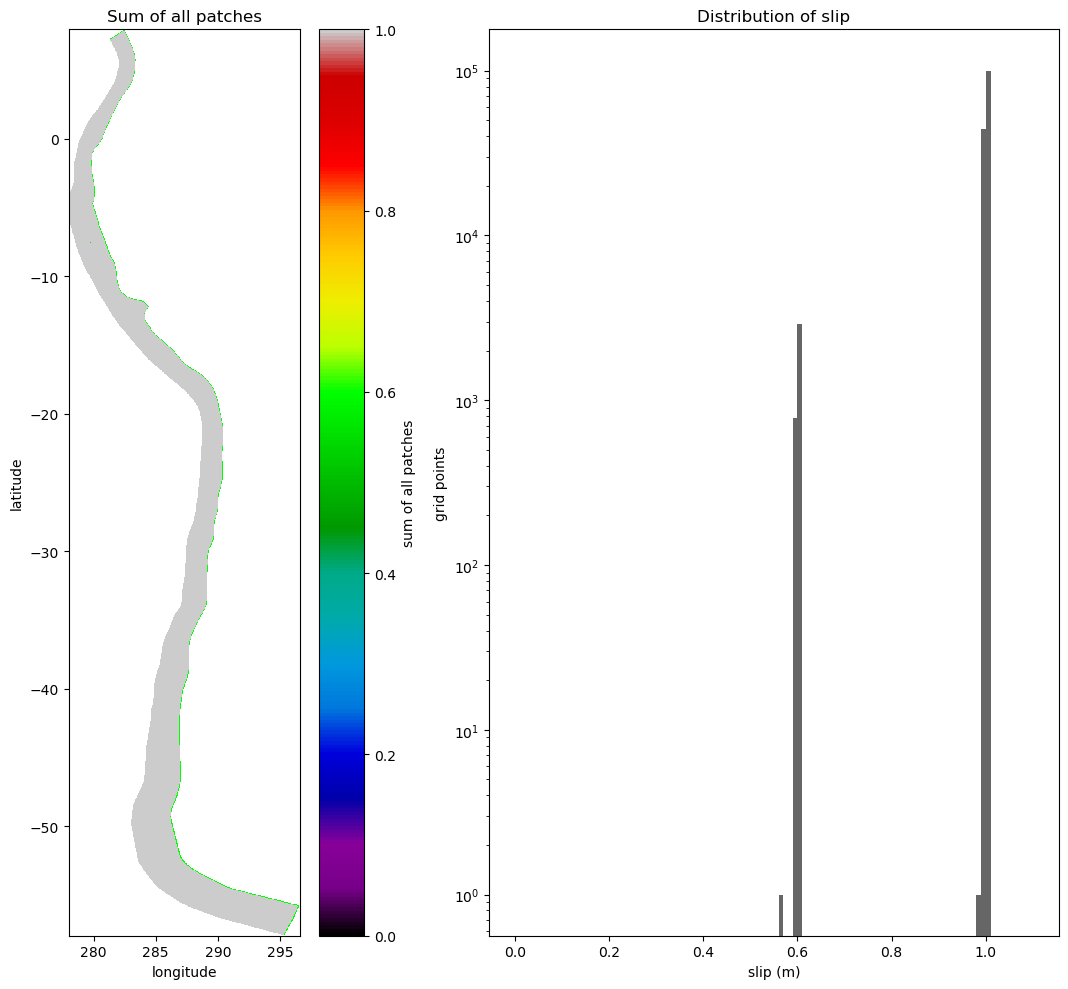

In [19]:
ref = read_vtk(run_patch(PLOT_CELL))[4].max()     # peak slip of one patch
print(f'peak slip of one patch = {ref:.3f}, largest summed slip = {np.nanmax(total):.3f}, '
      f'median summed slip = {np.nanmedian(total):.3f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 10), gridspec_kw={'width_ratios': [1, 1.5]})
ax = axes[0]
pcm = ax.pcolormesh(GX, GY, total, cmap='nipy_spectral', vmin=0, vmax= ref, shading='auto')
fig.colorbar(pcm, ax=ax, label='sum of all patches')
set_geo_aspect(ax, lat0)
ax.set(xlabel='longitude', ylabel='latitude', title='Sum of all patches')


axes[1].hist(total[on_fault], bins=np.linspace(0, 1.1 * ref, 111), color='0.4')
axes[1].set_yscale('log')
axes[1].set(xlabel='slip (m)', ylabel='grid points', title='Distribution of slip')
plt.tight_layout()
plt.show()

### Where does the sum differ from uniform?

Left: difference from the peak slip of a single patch, as a percentage. Right: histogram of the same quantity. Points that differ by more than `TOL` are coloured in the map. The values are negative because the sum cannot exceed the peak.

97.5% of the fault is within 1.0% of the peak slip


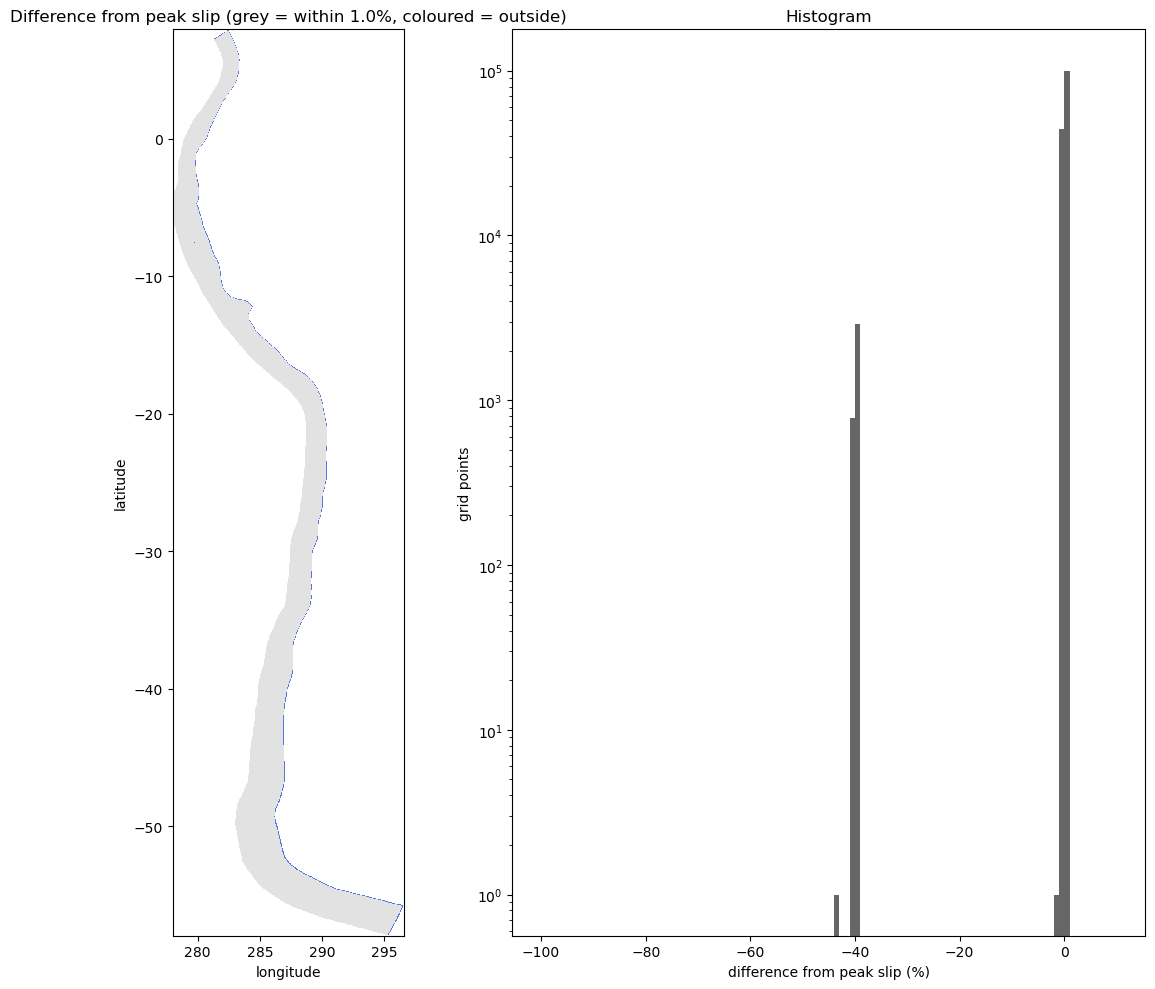

In [10]:
TOL = 1.0                                    # percent

dev = 100 * (total - ref) / ref
bad = np.abs(dev) > TOL
frac = np.nansum(~bad & on_fault) / on_fault.sum()
print(f'{100 * frac:.1f}% of the fault is within {TOL}% of the peak slip')

fig, axes = plt.subplots(1, 2, figsize=(11, 10), gridspec_kw={'width_ratios': [1, 1.5]})
ax = axes[0]
ax.pcolormesh(GX, GY, np.where(bad | ~on_fault, np.nan, 0.2), cmap='Greys', vmin=0, vmax=1, shading='auto')
ax.pcolormesh(GX, GY, np.where(bad & on_fault, dev, np.nan), cmap='coolwarm', vmin=-50, vmax=50, shading='auto')
set_geo_aspect(ax, lat0)
ax.set(xlabel='longitude', ylabel='latitude', title=f'Difference from peak slip (grey = within {TOL}%, coloured = outside)')

axes[1].hist(dev[on_fault], bins=np.linspace(-100, 10, 111), color='0.4')
axes[1].set_yscale('log')
axes[1].set(xlabel='difference from peak slip (%)', ylabel='grid points', title='Histogram')
plt.tight_layout()
plt.show()

**Reading the plots:** away from the fault boundary every point should be covered by neighbouring patches whose tapers add up to the same total, so the sum is flat. Close to the edge of the fault there are no neighbours to supply the missing tapers, so the sum falls off over roughly the taper length. If you see deviations in the interior, the usual suspects are failed patches (see above) or a quadrangle whose nodes are ordered differently from its neighbours (see `order_mesh.py`).